# Frente 4 · Validación, líneas base y primer XGBoost

Tareas 4.1 a 4.4 del plan del Predictor de rinde, sobre la **tabla maestra v1** (Santa Fe, 19 departamentos,
campañas 2000/01 a 2024/25 con rinde publicado).

| Tarea | Dónde |
| --- | --- |
| 4.1 Validación dejando una campaña afuera | sección 2 (`modelo.validar`) |
| 4.2 Líneas base: promedio histórico y tendencia lineal | sección 3 |
| 4.3 Primer XGBoost | sección 4 |
| 4.4 Métricas (MAE, % de error, R²) por cultivo y contra las líneas base | secciones 4 y 5 |

La lógica vive en `src/modelo.py`; este notebook solo la usa y muestra resultados. Para otra región:
dejar su tabla en `data/processed/<region>/tabla_maestra.csv` y poner `AGRO_REGION=<region>` antes de
abrir Jupyter.

**Regla de oro:** nunca hay filas de la misma campaña en entrenamiento y prueba. `modelo.validar` lo
verifica con un `assert` en cada pliegue, y todo lo que se aprende (promedios, rectas, el árbol) se
ajusta dentro del pliegue.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import modelo
pd.set_option("display.width", 160)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

df = modelo.cargar_tabla()
ent = modelo.entrenables(df)
print(modelo.REGION, "·", df.shape, "· filas con rinde:", len(ent))
ent.groupby("cultivo").agg(filas=("rinde_real", "size"), campanias=("campania", "nunique"),
                           deptos=("depto_id", "nunique"), rinde_medio=("rinde_real", "mean")).round(0)

santa_fe · (1026, 43) · filas con rinde: 945


,filas,campanias,deptos,rinde_medio
cultivo,,,,
maiz,470,25,19,6584.0
soja,475,25,19,2710.0


## 1. Datos disponibles

Huecos por columna en las filas con rinde, y cantidad de campañas por fase ENSO. Son pocas campañas
Niño (9 de 25, y solo 2 fuertes: 2015/16 y 2023/24), así que las conclusiones por fase van con cuidado.

In [2]:
huecos = ent.filter(regex="_mes_").isna().mean().mul(100).round(1)
print("columnas mensuales con huecos (%):", huecos[huecos > 0].to_dict() or "ninguna")
ent.drop_duplicates("campania").groupby("fase_enso")["campania"].apply(list)

columnas mensuales con huecos (%): ninguna


fase_enso
neutro    [2001/02, 2003/04, 2012/13, 2013/14, 2016/17, ...
nina      [2000/01, 2005/06, 2007/08, 2008/09, 2010/11, ...
nino      [2002/03, 2004/05, 2006/07, 2009/10, 2014/15, ...
Name: campania, dtype: object

## 2. Esquemas de validación (tarea 4.1)

- **`loco`** (*leave-one-campaign-out*, el del plan): se esconde una campaña entera, se entrena con las
  otras 24 y se predice la escondida. Se repite con cada campaña.
- **`temporal`** (origen móvil): para predecir la campaña *t* se entrena solo con campañas anteriores
  a *t* (desde 2008/09, para tener al menos 8 de historia). Es la situación real al predecir 2026/27.

Los dos respetan la regla de oro. La diferencia es que `loco` usa campañas **futuras** para entrenar,
y eso ayuda sobre todo a la tendencia lineal, que interpola en vez de extrapolar. Si un modelo gana
en `loco` pero no en `temporal`, la mejora no es real para el uso que queremos.

In [3]:
modelos = modelo.modelos_estandar(hasta_mes=8)   # con datos de toda la campaña (sep-abr)
pred = {e: modelo.validar(df, modelos, esquema=e) for e in ("loco", "temporal")}
pred["loco"].head()

,depto_id,departamento,campania,anio_siembra,cultivo,fase_enso,nino_fuerte,rinde_real,modelo,pred,error,esquema
0,82007,Belgrano,2000/01,2000,maiz,nina,False,7500.0,promedio_historico,8237.541667,737.541667,loco
1,82014,Caseros,2000/01,2000,maiz,nina,False,5440.0,promedio_historico,8425.333333,2985.333333,loco
2,82021,Castellanos,2000/01,2000,maiz,nina,False,4400.0,promedio_historico,6989.583333,2589.583333,loco
3,82028,Constitución,2000/01,2000,maiz,nina,False,5600.0,promedio_historico,7951.541667,2351.541667,loco
4,82035,Garay,2000/01,2000,maiz,nina,False,4400.0,promedio_historico,5873.173913,1473.173913,loco


## 3. Líneas base (tarea 4.2)

- **Promedio histórico:** rinde medio del departamento en las campañas de entrenamiento.
- **Tendencia lineal:** recta rinde ~ año por departamento, ajustada con las campañas de entrenamiento.

Son la vara mínima: un modelo que no las supera no aporta.

In [4]:
bases = ["promedio_historico", "tendencia_lineal"]
pd.concat({e: modelo.metricas(p[p.modelo.isin(bases)]) for e, p in pred.items()}, names=["esquema"])

mae_kg_ha  error_pct     r2  sesgo_kg_ha      n
esquema  modelo             cultivo                                                 
loco     promedio_historico maiz      1180.149     24.115  0.531        0.000  470.0
                            soja       499.595     25.510  0.403        0.000  475.0
         tendencia_lineal   maiz      1210.414     24.936  0.493       18.263  470.0
                            soja       506.218     26.067  0.373        2.805  475.0
temporal promedio_historico maiz      1269.948     26.093  0.450     -134.246  318.0
                            soja       596.388     30.014  0.324      -86.258  323.0
         tendencia_lineal   maiz      1391.900     30.153  0.306      525.350  318.0
                            soja       637.998     33.072  0.199       80.034  323.0

## 4. Primer XGBoost y comparación (tareas 4.3 y 4.4)

Un modelo por cultivo que aprende el **desvío respecto de una línea base del departamento** a partir de
NDVI, lluvia, temperatura y humedad del suelo de septiembre a abril, más el ONI. Predicción = base +
desvío. Se prueban las dos bases: `xgboost` (sobre la tendencia) y `xgboost_sobre_promedio`.

`mejora_vs_base_pct` = cuánto baja el MAE respecto de la tendencia lineal (positivo = mejor).

In [5]:
tabla = pd.concat({e: modelo.comparar_con_base(modelo.metricas(p)) for e, p in pred.items()}, names=["esquema"])
tabla

mae_kg_ha  error_pct     r2  sesgo_kg_ha      n  mejora_vs_base_pct
esquema  modelo                 cultivo                                                                     
loco     promedio_historico     maiz      1180.149     24.115  0.531        0.000  470.0                 2.5
                                soja       499.595     25.510  0.403        0.000  475.0                 1.3
         tendencia_lineal       maiz      1210.414     24.936  0.493       18.263  470.0                 0.0
                                soja       506.218     26.067  0.373        2.805  475.0                 0.0
         xgboost                maiz       975.538     19.380  0.695      -28.319  470.0                19.4
                                soja       374.561     17.293  0.650       40.895  475.0                26.0
         xgboost_sobre_promedio maiz       973.908     19.477  0.704      -24.520  470.0                19.5
                                soja       378.016     17.126  0.650       30.308  475.0                25.3
temporal promedio_historico     maiz      1269.948     26.093  0.450     -134.246  318.0                 8.8
                                soja       596.388     30.014  0.324      -86.258  323.0                 6.5
         tendencia_lineal       maiz      1391.900     30.153  0.306      525.350  318.0                 0.0
                                soja       637.998     33.072  0.199       80.034  323.0                 0.0
         xgboost                maiz      1095.881     21.885  0.603      232.968  318.0                21.3
                                soja       487.190     24.251  0.515       54.771  323.0                23.6
         xgboost_sobre_promedio maiz      1199.749     22.622  0.567     -482.432  318.0                13.8
                                soja       475.959     23.006  0.563     -120.001  323.0                25.4

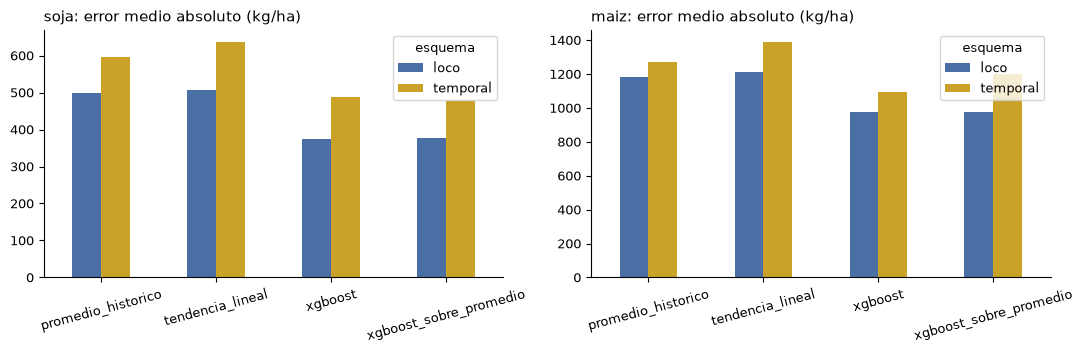

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
orden = ["promedio_historico", "tendencia_lineal", "xgboost", "xgboost_sobre_promedio"]
for a, cult in zip(ax, ["soja", "maiz"]):
    t = tabla.xs(cult, level="cultivo")["mae_kg_ha"].unstack("esquema").reindex(orden)
    t.plot.bar(ax=a, rot=15, color=["#4a6fa5", "#c9a227"])
    a.set_title(f"{cult}: error medio absoluto (kg/ha)", loc="left"); a.set_xlabel("")
plt.tight_layout(); plt.show()

## 5. ¿Se equivoca más en años Niño? (subpregunta 2)

Métricas por fase ENSO, con el esquema `loco`. Ojo con `n`: en años Niño hay 9 campañas × 19 departamentos.

In [7]:
por_fase = modelo.comparar_con_base(modelo.metricas(pred["loco"], por=("modelo", "cultivo", "fase_enso")))
por_fase[["mae_kg_ha", "error_pct", "r2", "sesgo_kg_ha", "n", "mejora_vs_base_pct"]].unstack("fase_enso").round(1)

mae_kg_ha                 error_pct                 r2           sesgo_kg_ha                     n                \
fase_enso                         neutro    nina    nino    neutro  nina  nino neutro nina nino      neutro    nina   nino neutro   nina   nino   
modelo                 cultivo                                                                                                                    
promedio_historico     maiz        846.3  1395.3  1170.0      13.1  38.1  16.3    0.7  0.2  0.6      -435.6  1094.4 -893.6  114.0  185.0  171.0   
                       soja        459.1   547.8   473.0      16.7  39.1  16.3    0.4  0.2  0.4      -162.1   366.6 -299.3  114.0  190.0  171.0   
tendencia_lineal       maiz        859.9  1451.5  1183.2      13.2  39.9  16.5    0.7  0.1  0.6      -455.0  1169.2 -911.4  114.0  185.0  171.0   
                       soja        444.9   572.8   473.2      16.2  40.7  16.4    0.4  0.2  0.4      -167.5   385.3 -308.7  114.0  190.0  171.0   
xgboost                maiz        896.2  1055.7   941.7      13.8  26.7  15.2    0.7  0.6  0.7      -460.7   346.1 -145.1  114.0  185.0  171.0   
                       soja        328.3   418.7   356.4      11.6  23.9  13.7    0.6  0.6  0.6      -124.1   149.6   30.1  114.0  190.0  171.0   
xgboost_sobre_promedio maiz        868.5  1084.9   924.1      13.7  27.3  14.9    0.7  0.6  0.7      -445.2   342.3 -140.9  114.0  185.0  171.0   
                       soja        318.2   415.1   376.6      11.2  23.2  14.4    0.6  0.6  0.6      -132.1   127.3   30.8  114.0  190.0  171.0   

                               mejora_vs_base_pct              
fase_enso                                  neutro  nina  nino  
modelo                 cultivo                                 
promedio_historico     maiz                   1.6   3.9   1.1  
                       soja                  -3.2   4.4   0.0  
tendencia_lineal       maiz                   0.0   0.0   0.0  
                       soja                   0.0   0.0   0.0  
xgboost                maiz                  -4.2  27.3  20.4  
                       soja                  26.2  26.9  24.7  
xgboost_sobre_promedio maiz                  -1.0  25.3  21.9  
                       soja                  28.5  27.5  20.4

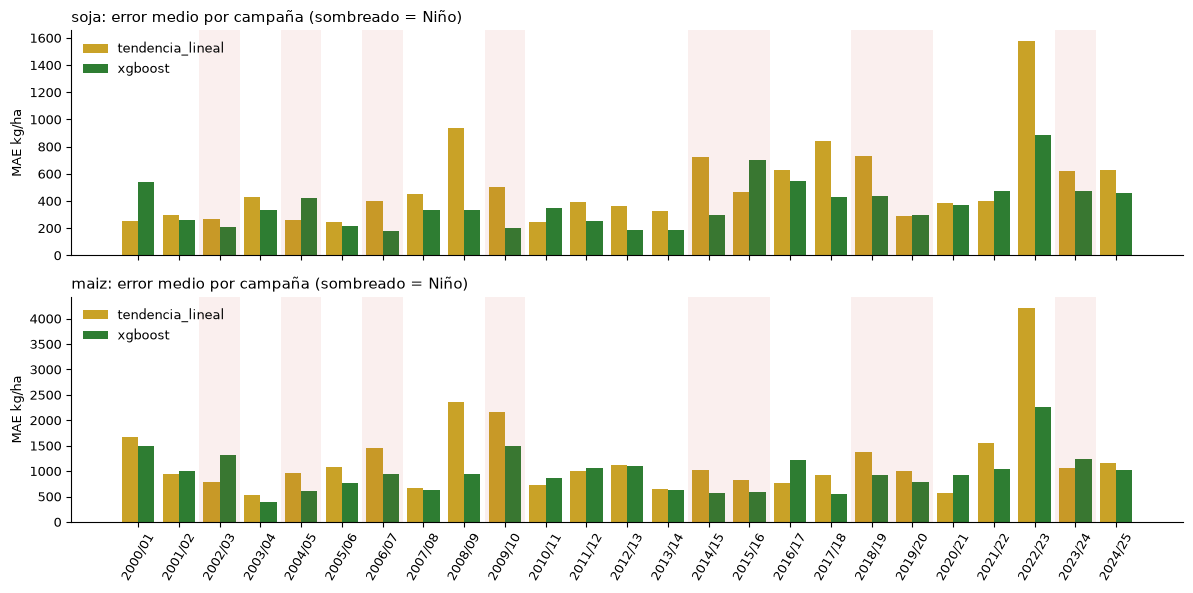

In [8]:
# Error por campaña: dónde falla cada modelo
camp = (pred["loco"].assign(abs_err=lambda x: x.error.abs())
        .groupby(["cultivo", "campania", "fase_enso", "modelo"])["abs_err"].mean().unstack("modelo"))
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for a, cult in zip(ax, ["soja", "maiz"]):
    c = camp.xs(cult, level="cultivo").reset_index()
    x = np.arange(len(c))
    for i, (m, col) in enumerate([("tendencia_lineal", "#c9a227"), ("xgboost", "#2e7d32")]):
        a.bar(x + (i - .5) * .4, c[m], width=.4, color=col, label=m)
    for xi, f in zip(x, c["fase_enso"]):
        if f == "nino":
            a.axvspan(xi - .5, xi + .5, color="#c0392b", alpha=.08, lw=0)
    a.set_xticks(x, c["campania"], rotation=60); a.set_ylabel("MAE kg/ha")
    a.set_title(f"{cult}: error medio por campaña (sombreado = Niño)", loc="left"); a.legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. Cómo baja el error a lo largo de la campaña (subpregunta 1)

Se reentrena el XGBoost usando solo los meses disponibles al momento de predecir: en diciembre hay
datos de septiembre a diciembre (`mes_1` a `mes_4`), en febrero hasta `mes_6`, y así. Las líneas base
no usan datos de la campaña, así que su error es el mismo en todos los meses.

In [9]:
filas = []
for corte, k in modelo.MESES_CORTE.items():
    feats = modelo.columnas_clima_satelite(k) + ["oni"]
    p = modelo.validar(df, {"xgboost": modelo.xgboost_sobre_tendencia(feats)}, esquema="loco")
    m = modelo.metricas(p).reset_index()
    m["corte"] = corte
    filas.append(m)
mes_a_mes = pd.concat(filas)
mes_a_mes.pivot(index="corte", columns="cultivo", values=["mae_kg_ha", "error_pct", "r2"]).reindex(list(modelo.MESES_CORTE)).round(2)

mae_kg_ha         error_pct           r2      
cultivo      maiz    soja      maiz   soja  maiz  soja
corte                                                 
dic        985.58  476.63     19.15  21.11  0.69  0.50
ene       1013.49  444.53     19.75  19.38  0.67  0.56
feb        993.34  389.56     19.53  17.87  0.68  0.64
mar        999.88  368.34     19.48  16.77  0.68  0.67
abr        975.54  374.56     19.38  17.29  0.70  0.65

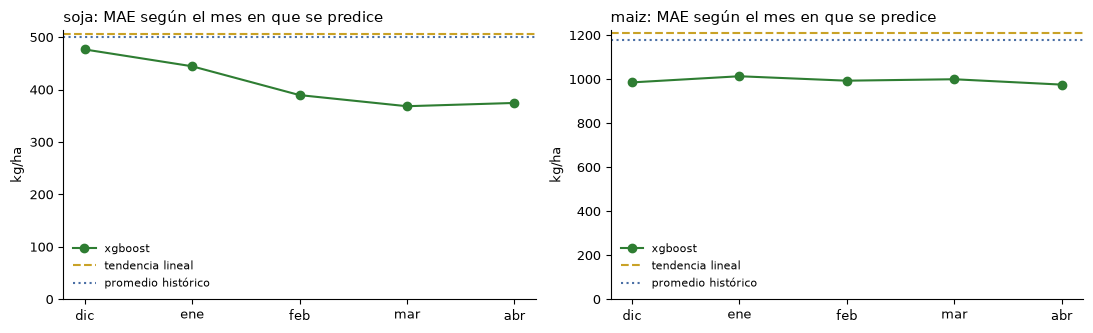

In [10]:
base_loco = modelo.metricas(pred["loco"])["mae_kg_ha"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, cult in zip(ax, ["soja", "maiz"]):
    s = mes_a_mes[mes_a_mes.cultivo == cult].set_index("corte").reindex(list(modelo.MESES_CORTE))["mae_kg_ha"]
    a.plot(s.index, s.values, marker="o", color="#2e7d32", label="xgboost")
    a.axhline(base_loco[("tendencia_lineal", cult)], color="#c9a227", ls="--", label="tendencia lineal")
    a.axhline(base_loco[("promedio_historico", cult)], color="#4a6fa5", ls=":", label="promedio histórico")
    a.set_title(f"{cult}: MAE según el mes en que se predice", loc="left"); a.set_ylabel("kg/ha")
    a.set_ylim(0, None); a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 7. Qué variables usa el modelo

Importancia por ganancia, con el modelo entrenado sobre todas las campañas. Es orientativa: con 25
campañas, las variables correlacionadas entre sí (NDVI de meses vecinos, lluvia y humedad del suelo) se
reparten la importancia.

In [11]:
from xgboost import XGBRegressor
feats = modelo.columnas_clima_satelite(8) + ["oni"]
imp = {}
for cult in ["soja", "maiz"]:
    tr = ent[ent.cultivo == cult]
    m = XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
                     min_child_weight=5, random_state=0)
    m.fit(tr[feats], tr.rinde_real - modelo.tendencia_lineal(tr, tr))
    imp[cult] = pd.Series(m.get_booster().get_score(importance_type="gain")).reindex(feats).fillna(0)
imp = pd.DataFrame(imp)
(imp / imp.sum()).sort_values("soja", ascending=False).head(12).round(3)

,soja,maiz
oni,0.130,0.278
ndvi_mes_4,0.130,0.066
humedad_suelo_mes_6,0.078,0.016
lluvia_mes_4,0.077,0.049
temp_mes_4,0.064,0.056
ndvi_mes_7,0.043,0.008
humedad_suelo_mes_5,0.042,0.010
temp_mes_7,0.039,0.061
lluvia_mes_5,0.038,0.021
lluvia_mes_6,0.034,0.025


## 8. Predicción de 2025/26 (todavía sin dato oficial por departamento)

La campaña 2025/26 ya tiene NDVI y clima completos, pero el MAGyP todavía no publicó el rinde por
departamento. Es una prueba en vivo: cuando salga el próximo CSV se compara contra esto.

In [12]:
f = modelo.xgboost_sobre_tendencia(feats)
nueva = df[df.campania == "2025/26"].copy()
nueva["pred_xgboost"] = f(ent, nueva)
nueva["pred_tendencia"] = modelo.tendencia_lineal(ent, nueva)
nueva["pred_promedio"] = modelo.promedio_historico(ent, nueva)
nueva.pivot_table(index="departamento", columns="cultivo", values=["pred_xgboost", "pred_tendencia"]).round(0)

pred_tendencia         pred_xgboost        
cultivo                    maiz    soja         maiz    soja
departamento                                                
9 de Julio               5168.0  2105.0       4513.0  2173.0
Belgrano                 7837.0  3475.0       7077.0  3067.0
Caseros                  8601.0  3376.0       7610.0  3113.0
Castellanos              7392.0  3518.0       6478.0  3556.0
Constitución             8049.0  2987.0       7108.0  2865.0
Garay                    6553.0  2662.0       5630.0  2528.0
General López            9276.0  3220.0       8296.0  3012.0
General Obligado         3701.0  1637.0       2538.0  1302.0
Iriondo                  7442.0  3398.0       6283.0  3157.0
La Capital               6578.0  2939.0       5486.0  3080.0
Las Colonias             6900.0  3211.0       6007.0  3418.0
Rosario                  7586.0  2689.0       6500.0  2408.0
San Cristóbal            6110.0  2527.0       5271.0  2577.0
San Javier               3666.0  1966.0       2869.0  1757.0
San Jerónimo             6985.0  3044.0       6196.0  2914.0
San Justo                6169.0  2788.0       5372.0  2851.0
San Lorenzo              7905.0  3079.0       7083.0  2809.0
San Martín               6932.0  3295.0       6076.0  3056.0
Vera                     4416.0  2062.0       3524.0  1780.0

## Notas para el equipo

- Las métricas cambian si cambia la tabla maestra (región, meses o máscara de cultivo): con cada
  versión nueva de la tabla hay que volver a correr este notebook.
- Próximos pasos del frente 4: búsqueda de hiperparámetros **dentro** de cada pliegue (validación
  anidada), probar variables derivadas (NDVI máximo, integral dic-mar, lluvia acumulada), y sumar el
  NDVI por cultivo cuando esté la máscara del INTA o MapBiomas (tarea 3.2).